# Mid-Atlantic & Northeast Coast: Flood Claims from Raw Data to Answers

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**Region:** Mid-Atlantic & Northeast Coast (NJ, NY, CT, RI, MA, MD, DE, DC, NH, ME). Dense, older cities and towns. Nor'easters and storm remnants cause flash floods; many homes have basements.

This notebook does everything for this region in one place: loading, cleaning, missing values, duplicates,
outliers, new features, encoding, feature selection, and the three research questions.

| RQ | Question | Family |
|---|---|---|
| RQ1 | How much will FEMA pay for the building? | Regression |
| RQ2 | Is this claim high severity (top 20% of building damage in this region)? | Classification |
| RQ3 | Do claims form groups with similar flood risk? | Clustering + PCA |

**Rules used everywhere**
- **Random 70/30 split over all years (2020-2025)**, random seed = 42. 70% of claims train the models, 30% test them.
- Every fill value, cut-off and scaler is computed from the **training part only**, so the test part stays unseen.
- Models only use facts known **when a claim is reported**.

**Why a random split, and what it means.** We want to know how well building and policy facts *explain* payments
and severity in this region. A random split tests this on claims the model has not seen, from all years.
Because claims from the same storm can be in both parts, the scores are **higher than for a completely new storm**.
Section 9.1 measures how much higher, so the reader knows the limit.

---
# Section 0: Setup and First Look

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression, f_classif
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix, silhouette_score, adjusted_rand_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, fcluster

SEED = 42
REGION = 'Mid-Atlantic & Northeast Coast'
STATES = ['NJ', 'NY', 'CT', 'RI', 'MA', 'MD', 'DE', 'DC', 'NH', 'ME']
DATA_PATH = '/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet'
pd.set_option('display.max_columns', 100)

full = pd.read_parquet(DATA_PATH)
df = full[full['yearOfLoss'].between(2020, 2025) & full['state'].isin(STATES)].reset_index(drop=True)
print(f'National file: {len(full):,} claims, {full.shape[1]} columns')
del full
print(f'{REGION} 2020-2025: {len(df):,} claims')
print()
print('Claims per state:')
print(df['state'].value_counts())

National file: 2,725,989 claims, 84 columns
Mid-Atlantic & Northeast Coast 2020-2025: 27,237 claims

Claims per state:
state
NJ    11089
NY     9276
MD     1779
CT     1451
ME     1119
MA     1113
NH      494
RI      458
DE      342
DC      116
Name: count, dtype: int64


In [2]:
MONEY_COLS = ['amountPaidOnBuildingClaim', 'amountPaidOnContentsClaim', 'amountPaidOnIncreasedCostOfComplianceClaim',
              'netBuildingPaymentAmount', 'netContentsPaymentAmount', 'netIccPaymentAmount', 'baseFloodElevation',
              'lowestAdjacentGrade', 'lowestFloorElevation', 'latitude', 'longitude', 'totalSalvageRecovery',
              'totalBldgClaimPmtRecovery', 'totalContentsClaimPmtRecovery', 'totalIccClaimPmtRecovery', 'totalSubrogationRecovery']
DATE_COLS = ['dateOfLoss', 'originalConstructionDate', 'originalNBDate', 'openDate', 'mostRecentPaymentDate', 'mostRecentRecoveryDate']
for c in MONEY_COLS:
    df[c] = df[c].astype(float)                      # stored as Decimal objects in the file
for c in DATE_COLS:
    d = pd.to_datetime(df[c].astype(str), format='%Y-%m-%d', errors='coerce')
    df[c] = d.where(d.dt.year >= 1800).astype('datetime64[ns]')   # impossible dates (e.g. year 1069) -> NaT

df['year'] = df['dateOfLoss'].dt.year
print('Claims per year (2025 is still incomplete in this snapshot):')
print(df['year'].value_counts().sort_index())

Claims per year (2025 is still incomplete in this snapshot):
year
2020     1254
2021    13877
2022     2358
2023     4483
2024     3868
2025     1397
Name: count, dtype: int64


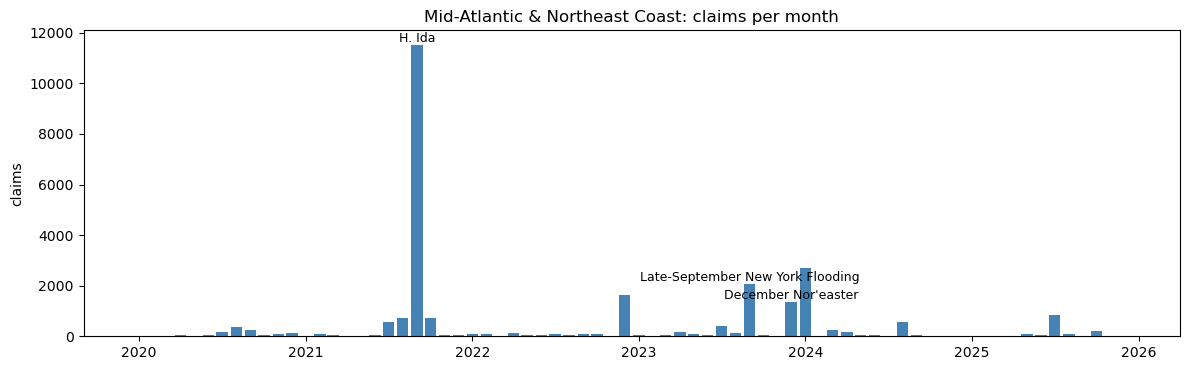

Claims from a named storm: 59%.  Top 3 storms: {'Hurricane Ida': 11388, 'Late-September New York Flooding': 1611, "December Nor'easter": 1207}


In [3]:
# Chart (interval, time): claims per month, with the three biggest named storms
monthly = df.groupby(df['dateOfLoss'].dt.to_period('M')).size()
monthly.index = monthly.index.to_timestamp()
plt.figure(figsize=(12, 3.8))
plt.bar(monthly.index, monthly.values, width=25, color='steelblue')
top_events = df['floodEvent'].value_counts().head(3)
for ev in top_events.index:
    when = df.loc[df['floodEvent'] == ev, 'dateOfLoss'].median().to_period('M').to_timestamp()
    plt.annotate(ev.replace('Hurricane ', 'H. '), (when, monthly.get(when, 0)), ha='center', va='bottom', fontsize=9)
plt.title(f'{REGION}: claims per month'); plt.ylabel('claims'); plt.tight_layout(); plt.show()
share = df['floodEvent'].notna().mean()
print(f'Claims from a named storm: {share:.0%}.  Top 3 storms: {top_events.to_dict()}')

---
# Section 1: Attribute Types

| Type | Meaning | Example |
|---|---|---|
| Nominal | labels, no order | state, flood zone |
| Binary | nominal with two values | elevated yes/no |
| Ordinal | labels with an order | CRS class 1-10 |
| Interval | differences matter, zero is not "nothing" | dates, water depth (can be negative) |
| Ratio | true zero | dollars, counts |

In [4]:
NOMINAL = ['ratedFloodZone', 'floodZoneCurrent', 'occupancyType', 'foundationType', 'basementEnclosureCrawlspaceType',
           'locationOfContents', 'obstructionType', 'buildingDescriptionCode', 'condominiumCoverageTypeCode',
           'elevationCertificateIndicator', 'disasterAssistanceCoverageRequired', 'rateMethod', 'causeOfDamage',
           'floodCharacteristicsIndicator', 'replacementCostBasis', 'floodEvent', 'eventDesignationNumber', 'ficoNumber',
           'nonPaymentReasonBuilding', 'nonPaymentReasonContents', 'state', 'reportedCity', 'reportedZipCode', 'countyCode',
           'censusGeoid', 'nfipRatedCommunityNumber', 'nfipCommunityNumberCurrent', 'nfipCommunityName', 'id']
BINARY = [c for c in df.columns if df[c].dtype == bool]
ORDINAL = ['crsClassCode', 'buildingDeductibleCode', 'contentsDeductibleCode', 'numberOfFloorsInTheInsuredBuilding']
INTERVAL = DATE_COLS + ['yearOfLoss', 'asOfDate', 'elevationDifference', 'baseFloodElevation', 'lowestFloorElevation',
                        'lowestAdjacentGrade', 'waterDepth', 'interiorWaterDepth', 'exteriorWaterDepth', 'latitude', 'longitude', 'year']
RATIO = [c for c in df.columns if c not in NOMINAL + BINARY + ORDINAL + INTERVAL]
types = pd.Series({**{c: 'nominal' for c in NOMINAL}, **{c: 'binary' for c in BINARY}, **{c: 'ordinal' for c in ORDINAL},
                   **{c: 'interval' for c in INTERVAL}, **{c: 'ratio' for c in RATIO}})
evidence = pd.DataFrame({'type': types, 'unique values': df[types.index].nunique(),
                         'example values': [df[c].dropna().unique()[:3].tolist() for c in types.index]})
print(types.value_counts())
print()
print('Proof for ordinal: crsClassCode values =', sorted(df['crsClassCode'].dropna().unique().tolist()))
print('Proof for interval: smallest waterDepth =', df['waterDepth'].min())
evidence.sort_values('type').head(12)

nominal     29
ratio       23
interval    18
binary      11
ordinal      4
Name: count, dtype: int64

Proof for ordinal: crsClassCode values = [3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]
Proof for interval: smallest waterDepth = -94.0


,type,unique values,example values
elevatedBuildingIndicator,binary,2,"[False, True]"
houseWorship,binary,2,"[False, True]"
nonProfitIndicator,binary,2,"[False, True]"
postFIRMConstructionIndicator,binary,2,"[False, True]"
smallBusinessIndicatorBuilding,binary,2,"[False, True]"
primaryResidenceIndicator,binary,2,"[True, False]"
floodproofedIndicator,binary,2,"[False, True]"
stateOwnedIndicator,binary,2,"[False, True]"
rentalPropertyIndicator,binary,2,"[False, True]"
preFirmIndicator,binary,2,"[False, True]"


---
# Section 2: Missing Values

## 2.1 Hidden missing values
Some blanks are stored as fake numbers. We find them first, then count.

In [5]:
has_bldg = df['totalBuildingInsuranceCoverage'] > 0
hidden = {
    'waterDepth == 99 (code for unknown)': df['waterDepth'] == 99,
    'interior / exterior depth >= 999 inches': (df['interiorWaterDepth'] >= 999) | (df['exteriorWaterDepth'] >= 999),
    'building value = $0 on an insured building': (df['buildingPropertyValue'] == 0) & has_bldg,
    'building damage = $1 (placeholder)': df['buildingDamageAmount'] == 1,
    'elevationDifference 500 ft or more': df['elevationDifference'].abs() >= 500,
}
for name, mask in hidden.items():
    print(f'{name:45s}: {mask.sum():>7,}')
print(f"Median payment on the '$1 damage' claims: ${df.loc[df['buildingDamageAmount'] == 1, 'netBuildingPaymentAmount'].median():,.0f}")

df.loc[df['waterDepth'] == 99, 'waterDepth'] = np.nan
df.loc[df['interiorWaterDepth'] >= 999, 'interiorWaterDepth'] = np.nan
df.loc[df['exteriorWaterDepth'] >= 999, 'exteriorWaterDepth'] = np.nan
df.loc[(df['buildingPropertyValue'] == 0) & has_bldg, 'buildingPropertyValue'] = np.nan
df.loc[(df['buildingReplacementCost'] == 0) & has_bldg, 'buildingReplacementCost'] = np.nan
df.loc[df['buildingDamageAmount'] == 1, 'buildingDamageAmount'] = np.nan
df.loc[df['elevationDifference'].abs() >= 500, 'elevationDifference'] = np.nan
print('Replaced with NaN.')

waterDepth == 99 (code for unknown)          :   1,266
interior / exterior depth >= 999 inches      :     128
building value = $0 on an insured building   :   1,887
building damage = $1 (placeholder)           :      20
elevationDifference 500 ft or more           :       0
Median payment on the '$1 damage' claims: $7,191
Replaced with NaN.


## 2.2 How much is missing?

Columns with blanks: 50 of 85.   Rows with no blank at all: 0


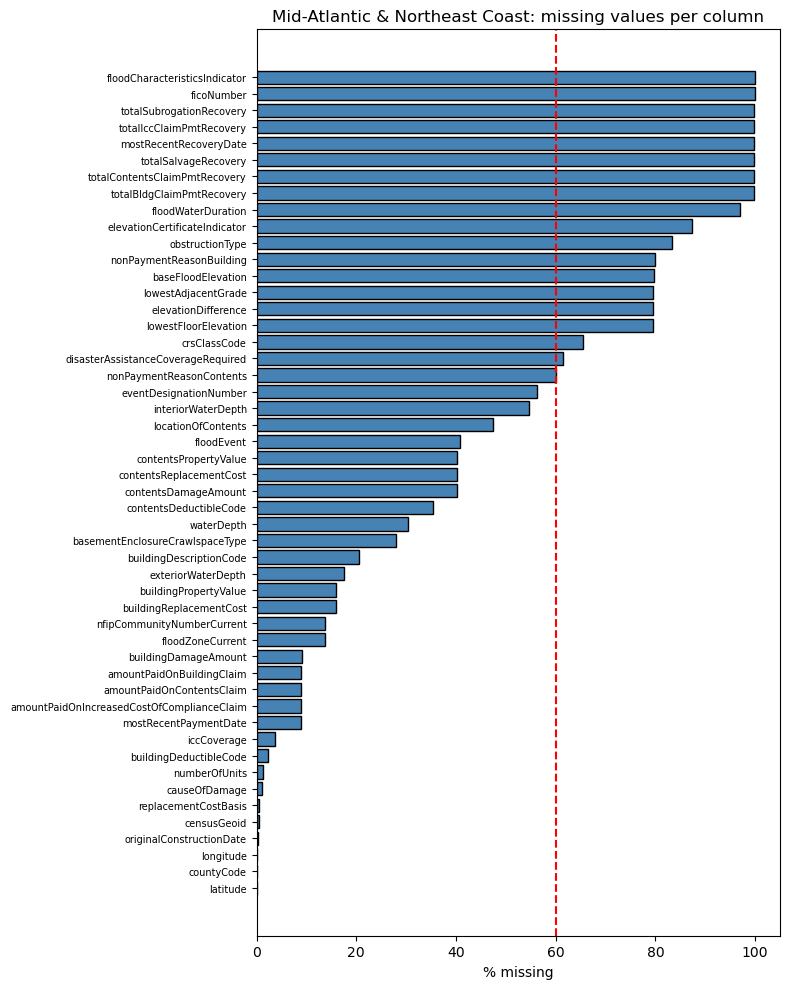

In [6]:
miss = (df.isna().mean() * 100).round(1)
miss = miss[miss > 0].sort_values(ascending=False)
print(f'Columns with blanks: {len(miss)} of {df.shape[1]}.   Rows with no blank at all: {len(df.dropna()):,}')
plt.figure(figsize=(8, 10))
plt.barh(miss.index, miss.values, color='steelblue', edgecolor='black'); plt.gca().invert_yaxis()
plt.axvline(60, color='red', ls='--'); plt.xlabel('% missing'); plt.yticks(fontsize=7)
plt.title(f'{REGION}: missing values per column'); plt.tight_layout(); plt.show()

## 2.3 Which kind of missing is it? (decided by code)

| Kind | Meaning | How the code decides |
|---|---|---|
| **not applicable** | the value does not exist | a "does not exist" column explains at least 90% of the blanks |
| **visible reason (MAR)** | the blank depends on a column we can see | % missing differs by 10+ points between legacy and Risk Rating 2.0 policies |
| **hidden reason (MNAR)** | the blank is linked to the claim itself | % of claims paid differs by 10+ points between blank and present |
| **no pattern (MCAR)** | blank by chance | under 1% missing and both gaps under 5 points |
| **empty** | always blank | 100% missing |
| **unclear** | none of the above | small gaps, more than 1% missing |

In [7]:
legacy = df['rateMethod'] != 'RE'
paid_b = df['netBuildingPaymentAmount'] > 0
no_cont = df['totalContentsInsuranceCoverage'].fillna(0) == 0
no_bldg = df['totalBuildingInsuranceCoverage'] == 0
NOT_APPLICABLE = {       # blank column : (a column that says "it does not exist", explanation)
    'amountPaidOnBuildingClaim': (df['netBuildingPaymentAmount'] == 0, 'no payment was made'),
    'amountPaidOnContentsClaim': (df['netContentsPaymentAmount'] == 0, 'no payment was made'),
    'amountPaidOnIncreasedCostOfComplianceClaim': (df['netIccPaymentAmount'] == 0, 'no payment was made'),
    'mostRecentPaymentDate': (~paid_b & (df['netContentsPaymentAmount'] <= 0), 'no payment, so no payment date'),
    'contentsDamageAmount': (no_cont, 'no contents insurance'),
    'contentsPropertyValue': (no_cont, 'no contents insurance'),
    'contentsReplacementCost': (no_cont, 'no contents insurance'),
    'contentsDeductibleCode': (no_cont, 'no contents insurance'),
    'locationOfContents': (no_cont, 'no contents insurance'),
    'buildingDeductibleCode': (no_bldg, 'no building insurance'),
    'obstructionType': (~df['elevatedBuildingIndicator'], 'building is not elevated'),
    'nonPaymentReasonBuilding': (paid_b, 'the claim was paid'),
    'nonPaymentReasonContents': (df['netContentsPaymentAmount'] > 0, 'the claim was paid'),
    'floodEvent': (df['eventDesignationNumber'].isna(), 'no named storm'),
    'eventDesignationNumber': (df['floodEvent'].isna(), 'no named storm'),
    'mostRecentRecoveryDate': (df['totalBldgClaimPmtRecovery'].isna(), 'no money recovered'),
    'floodZoneCurrent': (df['nfipCommunityNumberCurrent'].isna(), 'no current map lookup'),
}
for c in ['totalSalvageRecovery', 'totalBldgClaimPmtRecovery', 'totalContentsClaimPmtRecovery', 'totalIccClaimPmtRecovery', 'totalSubrogationRecovery']:
    NOT_APPLICABLE[c] = (df['mostRecentRecoveryDate'].isna(), 'no money recovered')

rows = []
for c in miss.index:
    m = df[c].isna()
    explained = (m & NOT_APPLICABLE[c][0]).sum() / m.sum() if c in NOT_APPLICABLE else 0.0
    rating_gap = 100 * (m[legacy].mean() - m[~legacy].mean()) if legacy.any() and (~legacy).any() else 0.0
    paid_gap = 100 * (paid_b[m].mean() - paid_b[~m].mean()) if (~m).any() else 0.0
    if m.mean() == 1:                    kind = 'empty'
    elif explained >= 0.9:               kind = 'not applicable'
    elif abs(rating_gap) >= 10:          kind = 'visible reason (MAR)'
    elif abs(paid_gap) >= 10:            kind = 'hidden reason (MNAR)'
    elif m.mean() < 0.01 and abs(rating_gap) < 5 and abs(paid_gap) < 5: kind = 'no pattern (MCAR)'
    else:                                kind = 'unclear'
    rows.append({'column': c, '% missing': miss[c], 'explained by "does not exist"': round(100 * explained, 1),
                 'legacy - RR2 gap': round(rating_gap, 1), 'paid gap': round(paid_gap, 1), 'kind': kind,
                 'reason': NOT_APPLICABLE[c][1] if explained >= 0.9 else ''})
kinds = pd.DataFrame(rows).set_index('column')
print(kinds['kind'].value_counts())
kinds

kind
not applicable          16
hidden reason (MNAR)    16
unclear                  9
visible reason (MAR)     6
empty                    2
no pattern (MCAR)        1
Name: count, dtype: int64


,% missing,"explained by ""does not exist""",legacy - RR2 gap,paid gap,kind,reason
column,,,,,,
floodCharacteristicsIndicator,100.0,0.0,0.0,0.0,empty,
ficoNumber,100.0,0.0,0.0,0.0,empty,
totalSubrogationRecovery,99.8,100.0,-0.1,-1.0,not applicable,no money recovered
totalIccClaimPmtRecovery,99.8,100.0,-0.1,-1.0,not applicable,no money recovered
mostRecentRecoveryDate,99.8,100.0,-0.1,-1.0,not applicable,no money recovered
totalSalvageRecovery,99.8,100.0,-0.1,-1.0,not applicable,no money recovered
totalContentsClaimPmtRecovery,99.8,100.0,-0.1,-1.0,not applicable,no money recovered
totalBldgClaimPmtRecovery,99.8,100.0,-0.1,-1.0,not applicable,no money recovered
floodWaterDuration,97.0,0.0,3.2,-10.8,hidden reason (MNAR),


---
# Section 3: Duplicates
`id` is unique for every row, so we compare all the other columns.

In [8]:
cols_no_id = [c for c in df.columns if c != 'id']
print('Duplicate id values                    :', df['id'].duplicated().sum())
print('Duplicate rows (all columns except id) :', df.duplicated(subset=cols_no_id).sum())
before = len(df)
df = df.drop_duplicates(subset=cols_no_id).reset_index(drop=True)
print(f'Rows before: {before:,}   after: {len(df):,}')

Duplicate id values                    : 0
Duplicate rows (all columns except id) : 8


Rows before: 27,237   after: 27,229

---
# Section 4: Columns We Drop

## 4.1 Leakage: which columns give away the answer?
We correlate every numeric column (and three "is this filled in?" flags) with the building payment.

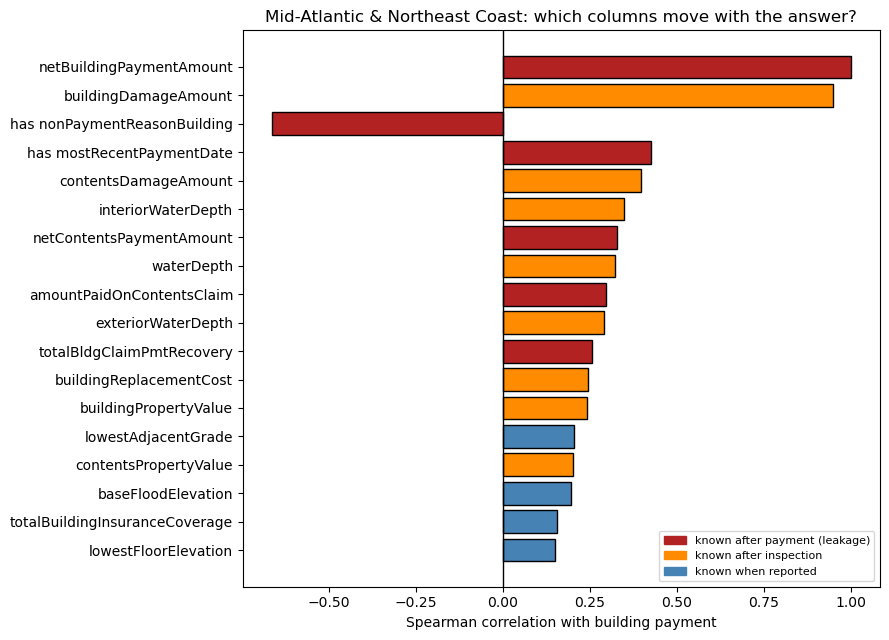

netBuildingPaymentAmount          1.000
buildingDamageAmount              0.948
has nonPaymentReasonBuilding     -0.663
has mostRecentPaymentDate         0.424
contentsDamageAmount              0.396
interiorWaterDepth                0.347
netContentsPaymentAmount          0.328
waterDepth                        0.321
amountPaidOnContentsClaim         0.295
exteriorWaterDepth                0.290
totalBldgClaimPmtRecovery         0.255
buildingReplacementCost           0.245
buildingPropertyValue             0.242
lowestAdjacentGrade               0.203
contentsPropertyValue             0.202
baseFloodElevation                0.197
totalBuildingInsuranceCoverage    0.155
lowestFloorElevation              0.149

Claims with no payment date that were paid: 0.0%
Claims with a non-payment reason that were paid: 1.6%


In [9]:
paid_b = df['netBuildingPaymentAmount'] > 0          # recomputed: duplicates were removed above
target = df['amountPaidOnBuildingClaim'].fillna(0)
check = df.select_dtypes(include='number').drop(columns=['amountPaidOnBuildingClaim', 'id', 'yearOfLoss', 'year'], errors='ignore')
check['has nonPaymentReasonBuilding'] = df['nonPaymentReasonBuilding'].notna().astype(int)
check['has mostRecentPaymentDate'] = df['mostRecentPaymentDate'].notna().astype(int)
check['has recovery amount'] = df['totalBldgClaimPmtRecovery'].notna().astype(int)
check = check.loc[:, check.nunique() > 1]
corr_t = check.corrwith(target, method='spearman').dropna()
top = corr_t.reindex(corr_t.abs().sort_values(ascending=False).index).head(18)

AFTER_PAYMENT = ['netBuildingPaymentAmount', 'netContentsPaymentAmount', 'amountPaidOnContentsClaim', 'netIccPaymentAmount',
                 'amountPaidOnIncreasedCostOfComplianceClaim', 'has nonPaymentReasonBuilding', 'has mostRecentPaymentDate',
                 'has recovery amount', 'totalBldgClaimPmtRecovery', 'totalContentsClaimPmtRecovery', 'totalSalvageRecovery',
                 'totalIccClaimPmtRecovery', 'totalSubrogationRecovery']
AFTER_INSPECTION = ['buildingDamageAmount', 'contentsDamageAmount', 'buildingPropertyValue', 'buildingReplacementCost',
                    'contentsPropertyValue', 'contentsReplacementCost', 'waterDepth', 'interiorWaterDepth', 'exteriorWaterDepth',
                    'floodWaterDuration']
colors = ['firebrick' if c in AFTER_PAYMENT else 'darkorange' if c in AFTER_INSPECTION else 'steelblue' for c in top.index]
plt.figure(figsize=(9, 6.5))
plt.barh(top.index[::-1], top.values[::-1], color=colors[::-1], edgecolor='black'); plt.axvline(0, color='black', lw=1)
plt.xlabel('Spearman correlation with building payment'); plt.title(f'{REGION}: which columns move with the answer?')
plt.legend(handles=[Patch(color='firebrick', label='known after payment (leakage)'), Patch(color='darkorange', label='known after inspection'),
                    Patch(color='steelblue', label='known when reported')], loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()
print(top.round(3).to_string())
print()
print(f"Claims with no payment date that were paid: {paid_b[df['mostRecentPaymentDate'].isna()].mean():.1%}")
print(f"Claims with a non-payment reason that were paid: {paid_b[df['nonPaymentReasonBuilding'].notna()].mean():.1%}")

## 4.2 The drop list, with computed proof

In [10]:
top_share = df.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
pct_missing = df.isna().mean()
DROP = {}
for c in df.columns:
    if pct_missing[c] == 1:                                   DROP[c] = 'empty'
    elif top_share[c] >= 0.995:                               DROP[c] = 'constant or almost constant'
for c in AFTER_PAYMENT + ['mostRecentPaymentDate', 'mostRecentRecoveryDate', 'nonPaymentReasonBuilding', 'nonPaymentReasonContents']:
    if c in df.columns: DROP.setdefault(c, 'leakage (known after payment)')
for c in ['contentsReplacementCost', 'floodWaterDuration']:
    DROP.setdefault(c, 'after inspection, not needed')
for c in ['baseFloodElevation', 'lowestFloorElevation', 'lowestAdjacentGrade', 'elevationCertificateIndicator', 'disasterAssistanceCoverageRequired']:
    if pct_missing[c] > 0.6: DROP.setdefault(c, 'more than 60% missing')
for c in ['id', 'nfipCommunityName', 'nfipRatedCommunityNumber', 'nfipCommunityNumberCurrent', 'reportedZipCode', 'censusGeoid']:
    DROP.setdefault(c, 'identifier / too many values')
DROP.setdefault('reportedCity', 'empty')
for c in ['yearOfLoss', 'eventDesignationNumber', 'floodZoneCurrent', 'preFirmIndicator', 'asOfDate']:
    DROP.setdefault(c, 'repeats another column')
drop_table = pd.DataFrame({'reason': DROP})
drop_table['% missing'] = (pct_missing[list(DROP)] * 100).round(1)
drop_table['unique values'] = df[list(DROP)].nunique()
drop_table['top value share %'] = (top_share[list(DROP)] * 100).round(1)
print('Columns dropped:', len(DROP))
print(drop_table['reason'].value_counts())
print()
print(f"Proof 'repeats': yearOfLoss = year(dateOfLoss) on {(df['yearOfLoss'] == df['year']).mean():.0%} of rows; "
      f"floodZoneCurrent = ratedFloodZone on {(df['floodZoneCurrent'] == df['ratedFloodZone'])[df['floodZoneCurrent'].notna()].mean():.0%}")
drop_table.sort_values('reason')

Columns dropped: 40
reason
constant or almost constant      14
leakage (known after payment)     7
identifier / too many values      6
more than 60% missing             5
repeats another column            4
empty                             2
after inspection, not needed      2
Name: count, dtype: int64

Proof 'repeats': yearOfLoss = year(dateOfLoss) on 100% of rows; floodZoneCurrent = ratedFloodZone on 96%


,reason,% missing,unique values,top value share %
contentsReplacementCost,"after inspection, not needed",40.2,668,50.4
floodWaterDuration,"after inspection, not needed",97.0,9,97.0
totalSubrogationRecovery,constant or almost constant,99.8,1,99.8
totalIccClaimPmtRecovery,constant or almost constant,99.8,1,99.8
totalContentsClaimPmtRecovery,constant or almost constant,99.8,9,99.8
totalBldgClaimPmtRecovery,constant or almost constant,99.8,27,99.8
mostRecentRecoveryDate,constant or almost constant,99.8,41,99.8
reportedCity,constant or almost constant,0.0,1,100.0
agricultureStructureIndicator,constant or almost constant,0.0,2,100.0
netIccPaymentAmount,constant or almost constant,0.0,4,99.9


---
# Section 5: Split, Then Fill Missing Values

We split first (random 70/30, seed 42), so all fill values come from the **training part** only.

| Strategy | Used for | Why |
|---|---|---|
| **0** | payment and contents damage when "not applicable" | the blank means $0 |
| **new category** ("unknown", "not_applicable") | category columns | the blank carries information |
| **training mode** | small category gaps | very few rows |
| **training median inside the same county** (then state, then all) | building value, water depth, coordinates, CRS class | nearby claims are similar |
| **not filled** | `buildingDamageAmount` | it builds the RQ2 target; we never invent the answer |

In [11]:
from sklearn.model_selection import train_test_split
train_idx, _ = train_test_split(df.index, test_size=0.3, random_state=SEED)
train = pd.Series(df.index.isin(train_idx), index=df.index)
test = ~train
print(f'Train (70%): {train.sum():,}   Test (30%): {test.sum():,}')
print('Claims per year in the test part:', df.loc[test, 'year'].value_counts().sort_index().to_dict())
work = df.copy()

# coding fix: legacy policies use old occupancy codes for the same building types
OLD_TO_NEW = {1: 11, 2: 12, 3: 13, 4: 18, 6: 18}
print('Old occupancy codes found:', work['occupancyType'].isin(OLD_TO_NEW).sum(), '-> translated to the new codes')
work['occupancyType'] = work['occupancyType'].replace(OLD_TO_NEW)

# not applicable -> 0 or a category
work.loc[work['amountPaidOnBuildingClaim'].isna() & (work['netBuildingPaymentAmount'] == 0), 'amountPaidOnBuildingClaim'] = 0
nc = work['totalContentsInsuranceCoverage'].fillna(0) == 0
for c in ['contentsDamageAmount', 'contentsPropertyValue']:
    work.loc[work[c].isna() & nc, c] = 0
for c in ['buildingPropertyValue', 'buildingReplacementCost']:
    work.loc[work[c].isna() & (work['totalBuildingInsuranceCoverage'] == 0), c] = 0
work['obstructionType'] = work['obstructionType'].astype('Int64').astype(str)
work.loc[~work['elevatedBuildingIndicator'] & (work['obstructionType'] == '<NA>'), 'obstructionType'] = 'not_applicable'
for c in ['obstructionType', 'basementEnclosureCrawlspaceType', 'locationOfContents', 'buildingDescriptionCode']:
    work[c] = work[c].astype(str).replace({'nan': 'unknown', '<NA>': 'unknown'})
for c in ['causeOfDamage', 'replacementCostBasis', 'buildingDeductibleCode', 'contentsDeductibleCode']:
    work[c] = work[c].fillna('unknown')
work['floodEvent'] = work['floodEvent'].fillna('no_named_event')

# training mode for small category gaps
for c in ['condominiumCoverageTypeCode', 'numberOfFloorsInTheInsuredBuilding', 'ratedFloodZone']:
    work[c] = work[c].fillna(work.loc[train, c].mode()[0])
work['totalContentsInsuranceCoverage'] = work['totalContentsInsuranceCoverage'].fillna(0)
work['numberOfUnits'] = work['numberOfUnits'].fillna(work.loc[train, 'numberOfUnits'].median())

# training median: county -> state -> all
def fill_from_train(col):
    out = work[col].copy()
    for key in ['countyCode', 'state']:
        med = work[train].groupby(key)[col].median()
        out = out.fillna(work[key].map(med))
    return out.fillna(work.loc[train, col].median())

FILL = ['buildingPropertyValue', 'buildingReplacementCost', 'waterDepth', 'interiorWaterDepth', 'exteriorWaterDepth',
        'latitude', 'longitude', 'crsClassCode']
compare = {}
for c in FILL:
    work[c + '_missing'] = work[c].isna().astype(int)
    if c == 'buildingPropertyValue':
        compare['global median'] = work[c].fillna(work.loc[train, c].median())
    work[c] = fill_from_train(c)
compare['county median'] = work['buildingPropertyValue']
print('Filled with training medians:', FILL)

Train (70%): 19,060   Test (30%): 8,169
Claims per year in the test part: {2020: 378, 2021: 4119, 2022: 688, 2023: 1358, 2024: 1195, 2025: 431}
Old occupancy codes found: 3804 -> translated to the new codes


Filled with training medians: ['buildingPropertyValue', 'buildingReplacementCost', 'waterDepth', 'interiorWaterDepth', 'exteriorWaterDepth', 'latitude', 'longitude', 'crsClassCode']


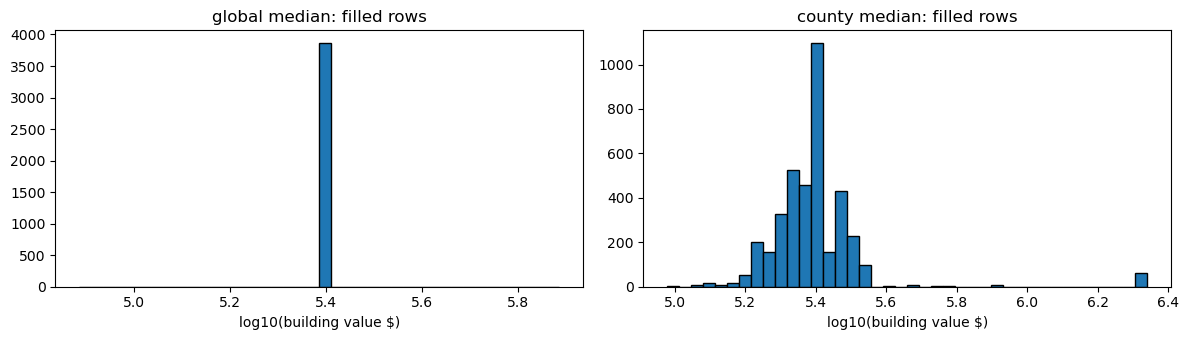

Different values given to the blanks: global median = 1, county median = 148


In [12]:
# Does the county median keep more of the real spread than one global value?
blank = work['buildingPropertyValue_missing'] == 1
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, (name, s) in zip(ax, compare.items()):
    a.hist(np.log10(s[blank].clip(lower=1)), bins=40, edgecolor='black'); a.set_title(f'{name}: filled rows')
    a.set_xlabel('log10(building value $)')
plt.tight_layout(); plt.show()
print(f"Different values given to the blanks: global median = {compare['global median'][blank].nunique()}, "
      f"county median = {compare['county median'][blank].nunique()}")

---
# Section 6: Outliers and Noise

Building payment: median $16,826, mean $37,870, max $3,231,281, skew 8.8
Five largest payments are within the coverage bought: [True, True, True, True, True] -> real outliers, we keep them

Noise rules:
   negative payment             : 3
   payment above coverage       : 46
   built after the flood        : 2
   policy started after flood   : 679
   claim opened before flood    : 11


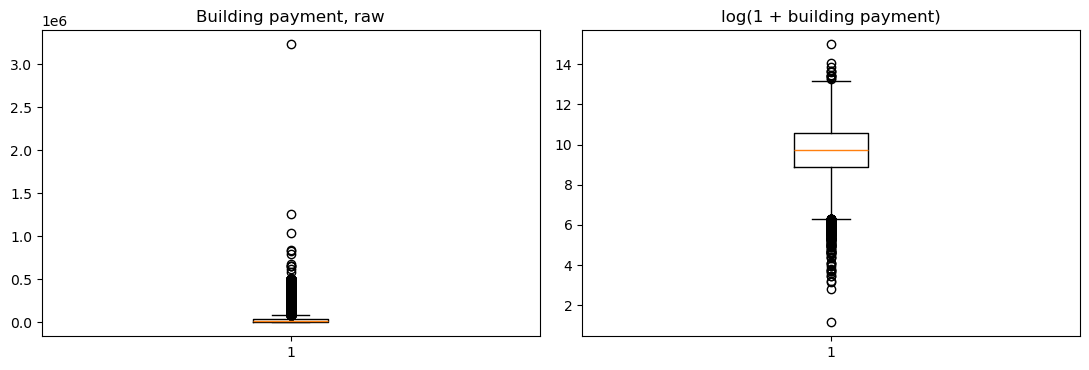

In [13]:
pay = work.loc[work['amountPaidOnBuildingClaim'] > 0, 'amountPaidOnBuildingClaim']
print(f'Building payment: median ${pay.median():,.0f}, mean ${pay.mean():,.0f}, max ${pay.max():,.0f}, skew {pay.skew():.1f}')
top5 = work.nlargest(5, 'amountPaidOnBuildingClaim')
print('Five largest payments are within the coverage bought:',
      (top5['amountPaidOnBuildingClaim'] <= top5['totalBuildingInsuranceCoverage']).tolist(), '-> real outliers, we keep them')

age_days = (work['dateOfLoss'] - work['originalConstructionDate']).dt.days
print()
print('Noise rules:')
print('   negative payment             :', (work['amountPaidOnBuildingClaim'] < 0).sum())
print('   payment above coverage       :', (work['amountPaidOnBuildingClaim'] > work['totalBuildingInsuranceCoverage'] + 1).sum())
print('   built after the flood        :', (age_days < 0).sum())
print('   policy started after flood   :', (work['originalNBDate'] > work['dateOfLoss']).sum())
print('   claim opened before flood    :', (work['openDate'] < work['dateOfLoss']).sum())
work['amountPaidOnBuildingClaim'] = work['amountPaidOnBuildingClaim'].clip(lower=0)
work.loc[age_days < 0, 'originalConstructionDate'] = pd.NaT
work.loc[work['originalNBDate'] > work['dateOfLoss'], 'originalNBDate'] = pd.NaT

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].boxplot(pay); ax[0].set_title('Building payment, raw')
ax[1].boxplot(np.log1p(pay)); ax[1].set_title('log(1 + building payment)')
plt.tight_layout(); plt.show()

---
# Section 7: New Features

| Feature | How | Why |
|---|---|---|
| `building_age` | loss date − construction date (training median if unknown) | older buildings predate flood rules |
| `report_lag_days` | open date − loss date | late reports often mean small claims |
| `flood_zone_family` | 52 zone codes → 7 groups | FEMA's risk groups |
| `is_named_event` | named storm or not | hurricane claims differ |
| `loss_month` | month of the loss | hurricane season |
| `bldg_deductible_usd` | deductible code → dollars | ordinal code with real values |
| `log_paid_building` | log(1 + payment) | RQ1 target |
| `high_severity` | damage ≥ 80th percentile of the training part, **in this region** | RQ2 target |

In [14]:
work['building_age'] = (work['dateOfLoss'] - work['originalConstructionDate']).dt.days / 365.25
work['building_age'] = work['building_age'].fillna(work.loc[train, 'building_age'].median())
work['report_lag_days'] = (work['openDate'] - work['dateOfLoss']).dt.days.clip(lower=0, upper=365)
work['report_lag_days'] = work['report_lag_days'].fillna(work.loc[train, 'report_lag_days'].median())
def zone_family(z):
    z = str(z).upper()
    if z in ['X', 'B', 'C']: return 'X'
    if z.startswith('V'): return 'V'
    if z in ['AE', 'AH', 'AO', 'A99', 'A']: return z
    if z.startswith('A'): return 'AE'
    return 'other'
work['flood_zone_family'] = work['ratedFloodZone'].map(zone_family)
work['is_named_event'] = (work['floodEvent'] != 'no_named_event').astype(int)
work['loss_month'] = work['dateOfLoss'].dt.month
DEDUCTIBLE_USD = {'0': 500, '1': 1000, '2': 2000, '3': 3000, '4': 4000, '5': 5000, '9': 750, 'A': 10000, 'B': 15000,
                  'C': 20000, 'D': 25000, 'E': 50000, 'F': 1250, 'G': 1500, 'H': 200}
work['bldg_deductible_usd'] = work['buildingDeductibleCode'].map(DEDUCTIBLE_USD).fillna(0)
work['log_paid_building'] = np.log1p(work['amountPaidOnBuildingClaim'])
work['is_paid'] = (work['amountPaidOnBuildingClaim'] > 0).astype(int)
threshold = work.loc[train, 'buildingDamageAmount'].quantile(0.80)
work['high_severity'] = np.where(work['buildingDamageAmount'].isna(), np.nan, (work['buildingDamageAmount'] >= threshold).astype(float))
print(f'High severity in {REGION} = building damage of ${threshold:,.0f} or more (80th percentile of the training part)')
print(f"Share high severity: train {work.loc[train, 'high_severity'].mean():.1%}, test {work.loc[test, 'high_severity'].mean():.1%}")

High severity in Mid-Atlantic & Northeast Coast = building damage of $44,302 or more (80th percentile of the training part)
Share high severity: train 20.0%, test 19.5%


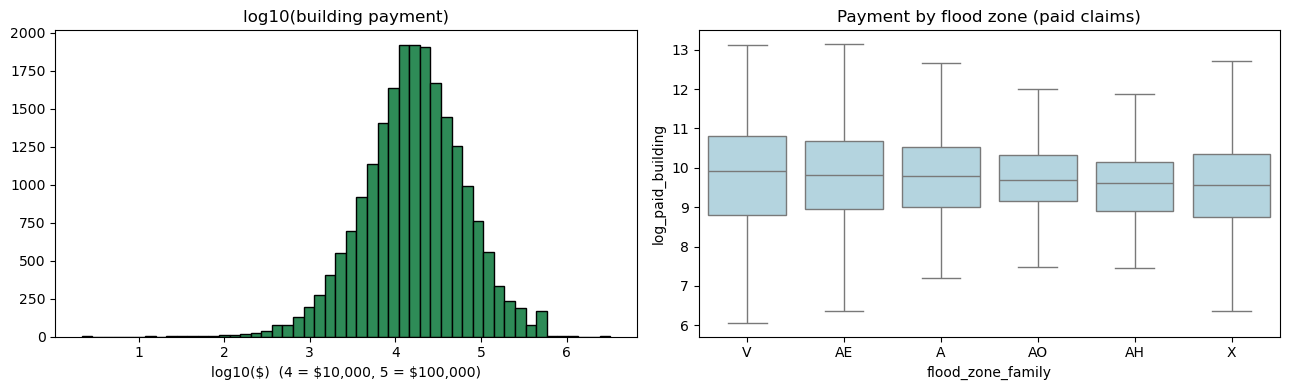

                   count   median
flood_zone_family                
V                    423  20486.0
AE                 13431  18393.0
A                    549  17746.0
AO                   464  16202.0
AH                   141  14995.0
X                   6044  14225.0


In [15]:
# Charts: the RQ1 target (ratio) and the new flood_zone_family feature (nominal vs ratio)
paid_claims = work[work['amountPaidOnBuildingClaim'] > 0]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(np.log10(pay), bins=50, edgecolor='black', color='seagreen'); ax[0].set_title('log10(building payment)')
ax[0].set_xlabel('log10($)  (4 = $10,000, 5 = $100,000)')
order = paid_claims.groupby('flood_zone_family')['log_paid_building'].median().sort_values(ascending=False).index
sns.boxplot(data=paid_claims, x='flood_zone_family', y='log_paid_building', order=order, showfliers=False, color='lightblue', ax=ax[1])
ax[1].set_title('Payment by flood zone (paid claims)')
plt.tight_layout(); plt.show()
print(paid_claims.groupby('flood_zone_family')['amountPaidOnBuildingClaim'].agg(['count', 'median']).sort_values('median', ascending=False).round(0))

---
# Section 8: Encoding and Scaling
Binary → 0/1, ordinal → numbers in order, nominal → one-hot. Money and count columns get a log before scaling.

In [16]:
for c in ['elevatedBuildingIndicator', 'postFIRMConstructionIndicator', 'primaryResidenceIndicator', 'rentalPropertyIndicator',
          'smallBusinessIndicatorBuilding', 'nonProfitIndicator']:
    work[c] = work[c].astype(int)
NOMINAL_FEATURES = ['flood_zone_family', 'foundationType', 'occupancyType', 'basementEnclosureCrawlspaceType',
                    'obstructionType', 'condominiumCoverageTypeCode', 'numberOfFloorsInTheInsuredBuilding'] + ['state']
NUMERIC_FEATURES = ['totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'policyCount', 'numberOfUnits',
                    'building_age', 'report_lag_days', 'crsClassCode', 'bldg_deductible_usd', 'loss_month', 'latitude', 'longitude',
                    'elevatedBuildingIndicator', 'postFIRMConstructionIndicator', 'primaryResidenceIndicator',
                    'rentalPropertyIndicator', 'smallBusinessIndicatorBuilding', 'nonProfitIndicator', 'is_named_event',
                    'crsClassCode_missing']
LOG_COLS = ['totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'policyCount', 'numberOfUnits']
X_all = pd.get_dummies(work[NOMINAL_FEATURES + NUMERIC_FEATURES], columns=NOMINAL_FEATURES, dtype=int)
print(f'Columns before encoding: {len(NOMINAL_FEATURES + NUMERIC_FEATURES)}   after: {X_all.shape[1]}')
print('Shape of the cleaned table:', work.drop(columns=list(DROP), errors='ignore').shape)

def for_linear(X):
    X = X.copy()
    for c in LOG_COLS:
        if c in X.columns: X[c] = np.log1p(X[c])
    return X

Columns before encoding: 27   after: 83
Shape of the cleaned table: (27229, 62)


---
# Section 9: Feature Selection (training part only)
1. drop near-constant columns · 2. drop one of each pair with correlation > 0.8 · 3. leave out latitude and longitude (proof in 9.1) ·
4. `SelectKBest` · 5. random forest importance · 6. compare with cross validation, then keep the **top 15 by random forest**.

In [17]:
rows1 = work['is_paid'] == 1
rows2 = work['high_severity'].notna()
s1 = work[train & rows1].sample(min(30000, (train & rows1).sum()), random_state=SEED).index
s2 = work[train & rows2].sample(min(30000, (train & rows2).sum()), random_state=SEED).index
y1, y2 = work['log_paid_building'], work['high_severity'].fillna(0).astype(int)

vt = VarianceThreshold(threshold=0.01).fit(X_all.loc[s1])
kept = X_all.columns[vt.get_support()]
corr = X_all.loc[s1, kept].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if any(upper[c] > 0.8)]
CAND = [c for c in kept if c not in to_drop]
print(f'{X_all.shape[1]} columns -> {len(kept)} after VarianceThreshold -> {len(CAND)} after dropping correlated pairs')
print('Dropped as correlated (> 0.8):', to_drop)

83 columns -> 60 after VarianceThreshold -> 55 after dropping correlated pairs
Dropped as correlated (> 0.8): ['policyCount', 'flood_zone_family_X', 'obstructionType_not_applicable', 'condominiumCoverageTypeCode_A', 'condominiumCoverageTypeCode_N']


In [18]:
K = 15
COORDS = ['latitude', 'longitude']
def rank_by_forest(cols):
    r1 = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED).fit(X_all.loc[s1, cols], y1[s1])
    r2 = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight='balanced', n_jobs=-1, random_state=SEED).fit(X_all.loc[s2, cols], y2[s2])
    return (pd.Series(r1.feature_importances_, index=cols).sort_values(ascending=False),
            pd.Series(r2.feature_importances_, index=cols).sort_values(ascending=False))
imp1_c, imp2_c = rank_by_forest(CAND)                          # with coordinates, only for the proof in 9.1
CAND = [c for c in CAND if c not in COORDS]
kb1 = X_all.loc[s1, CAND].columns[SelectKBest(f_regression, k=K).fit(X_all.loc[s1, CAND], y1[s1]).get_support()].tolist()
kb2 = X_all.loc[s2, CAND].columns[SelectKBest(f_classif, k=K).fit(X_all.loc[s2, CAND], y2[s2]).get_support()].tolist()
imp1, imp2 = rank_by_forest(CAND)

def cv_score(model, X, y, scoring):
    return cross_val_score(model, X, y, cv=3, scoring=scoring).mean()
reg = RandomForestRegressor(n_estimators=60, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
cls = RandomForestClassifier(n_estimators=60, min_samples_leaf=20, class_weight='balanced', n_jobs=-1, random_state=SEED)
fs = pd.DataFrame({
    'columns': [len(CAND), K, K],
    'RQ1 R2 (CV)': [cv_score(reg, X_all.loc[s1, c], y1[s1], 'r2') for c in [CAND, kb1, list(imp1.index[:K])]],
    'RQ2 ROC-AUC (CV)': [cv_score(cls, X_all.loc[s2, c], y2[s2], 'roc_auc') for c in [CAND, kb2, list(imp2.index[:K])]],
}, index=['all candidates', f'top {K} SelectKBest', f'top {K} random forest'])
FEAT_RQ1, FEAT_RQ2 = list(imp1.index[:K]), list(imp2.index[:K])
print(fs.round(3))
print()
print('RQ1 features:', FEAT_RQ1)
print('RQ2 features:', FEAT_RQ2)

                      columns  RQ1 R2 (CV)  RQ2 ROC-AUC (CV)
all candidates             53        0.256             0.797
top 15 SelectKBest         15        0.209             0.766
top 15 random forest       15        0.242             0.790

RQ1 features: ['totalBuildingInsuranceCoverage', 'building_age', 'report_lag_days', 'foundationType_1', 'is_named_event', 'crsClassCode', 'totalContentsInsuranceCoverage', 'loss_month', 'foundationType_2', 'bldg_deductible_usd', 'occupancyType_15.0', 'numberOfUnits', 'state_NJ', 'flood_zone_family_AE', 'crsClassCode_missing']
RQ2 features: ['totalBuildingInsuranceCoverage', 'report_lag_days', 'foundationType_2', 'building_age', 'occupancyType_18.0', 'primaryResidenceIndicator', 'foundationType_1', 'is_named_event', 'totalContentsInsuranceCoverage', 'occupancyType_11.0', 'bldg_deductible_usd', 'crsClassCode', 'loss_month', 'basementEnclosureCrawlspaceType_1.0', 'numberOfUnits']


## 9.1 Why we leave out latitude and longitude (and how optimistic the random split is)

We train the same random forest **with** and **without** the coordinates and test it two ways:
- on our **random 30% test part** (storms already seen in training), and
- on **new storms**: train on 2020-2023, test on 2024-2025.

In [19]:
old, new = df['year'] <= 2023, df['year'] >= 2024
F1c = list(imp1_c.index[:K]); F2c = list(imp2_c.index[:K])
def forest_r(): return RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
def forest_c(): return RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight='balanced', n_jobs=-1, random_state=SEED)
rows = []
for label, f1c, f2c in [('with coordinates', F1c, F2c), ('without coordinates', FEAT_RQ1, FEAT_RQ2)]:
    row = {'features': label}
    for test_name, a, b in [('random test', train, test), ('new storms', old, new)]:
        a1, b1, a2, b2 = a & rows1, b & rows1, a & rows2, b & rows2
        row[f'RQ1 R2, {test_name}'] = r2_score(y1[b1], forest_r().fit(X_all.loc[a1, f1c], y1[a1]).predict(X_all.loc[b1, f1c]))
        row[f'RQ2 F1, {test_name}'] = f1_score(y2[b2], forest_c().fit(X_all.loc[a2, f2c], y2[a2]).predict(X_all.loc[b2, f2c]))
    rows.append(row)
coord_check = pd.DataFrame(rows).set_index('features')
print('Coordinates in the top 15 (with coordinates): RQ1', [c for c in F1c if c in COORDS], ' RQ2', [c for c in F2c if c in COORDS])
coord_check.round(3)

Coordinates in the top 15 (with coordinates): RQ1 ['longitude', 'latitude']  RQ2 ['latitude', 'longitude']


,"RQ1 R2, random test","RQ2 F1, random test","RQ1 R2, new storms","RQ2 F1, new storms"
features,,,,
with coordinates,0.300,0.532,0.103,0.387
without coordinates,0.266,0.519,0.085,0.388


**Reading the check.** Here the coordinates help a little in **both** tests (RQ1 R² 0.300 vs 0.266 on the random test,
0.103 vs 0.085 on new storms; RQ2 F1 almost equal). So in this region they do **not** cause the memorising problem.
We still leave them out to use **one rule for all regions**; the cost is about 0.02-0.03 R².

On new storms the payment model is weak (R² about 0.09) compared with the random test (0.27).

---
# Section 10: RQ1 Regression: Can we predict the dollar amount paid on a building claim?

Paid claims only. The question asks for **dollars**, so the main scores are on the dollar scale:
**R² in dollars** and the **error in dollars**. We compare four models:

| Model | Trained on | Why |
|---|---|---|
| Baseline | always the training median | a model must beat this |
| Ridge | log(1 + payment) | simple linear model |
| Random forest | log(1 + payment) | trees, no straight-line assumption |
| **Gradient boosting (Poisson loss)** | **dollars** | trees built one after another, each fixing the last one's errors. Poisson loss fits money: always positive, a few very large values |

For the two log models we turn the prediction back into dollars before scoring. We also show R² on the log scale as a side note.

In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor
tr1, te1 = train & rows1, test & rows1
usd = work['amountPaidOnBuildingClaim']
X1, X1_lin = X_all[FEAT_RQ1], for_linear(X_all[FEAT_RQ1])
print('Leakage check: after-payment or after-inspection columns in the features:',
      [c for c in FEAT_RQ1 if any(c.startswith(a) for a in AFTER_PAYMENT + AFTER_INSPECTION)])
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
def boosting():
    return HistGradientBoostingRegressor(loss='poisson', max_iter=400, learning_rate=0.05, random_state=SEED)
gb = boosting()
cv = KFold(5, shuffle=True, random_state=SEED)
print('5-fold CV on the training part:')
print(f"   Ridge (log)          R2 log    {cross_val_score(ridge, X1_lin.loc[s1], y1[s1], cv=cv, scoring='r2').mean():.3f}")
print(f"   Random forest (log)  R2 log    {cross_val_score(forest, X1.loc[s1], y1[s1], cv=cv, scoring='r2').mean():.3f}")
print(f"   Boosting (dollars)   R2 dollars {cross_val_score(gb, X1.loc[s1], usd[s1], cv=cv, scoring='r2').mean():.3f}")

ridge.fit(X1_lin[tr1], y1[tr1]); forest.fit(X1[tr1], y1[tr1]); gb.fit(X1[tr1], usd[tr1])
def scores(name, p_usd):
    t = usd[te1]
    return {'model': name, 'R2 dollars': r2_score(t, p_usd), 'median error $': np.median(np.abs(t - p_usd)),
            'mean error $': mean_absolute_error(t, p_usd), 'R2 log (side note)': r2_score(np.log1p(t), np.log1p(np.clip(p_usd, 0, None)))}
p_gb = gb.predict(X1[te1])
rq1 = pd.DataFrame([scores('Baseline (median)', np.full(te1.sum(), usd[tr1].median())),
                    scores('Ridge (log -> $)', np.expm1(ridge.predict(X1_lin[te1]))),
                    scores('Random forest (log -> $)', np.expm1(forest.predict(X1[te1]))),
                    scores('Gradient boosting ($)', p_gb)]).set_index('model')
print(f'Paid claims in the 30% test part: {te1.sum():,}   median payment: ${usd[te1].median():,.0f}')
rq1.round(3)

Leakage check: after-payment or after-inspection columns in the features: []
5-fold CV on the training part:
   Ridge (log)          R2 log    0.140


   Random forest (log)  R2 log    0.255


   Boosting (dollars)   R2 dollars 0.296


Paid claims in the 30% test part: 6,262   median payment: $16,286


,R2 dollars,median error $,mean error $,R2 log (side note)
model,,,,
Baseline (median),-0.097,12247.610,30533.826,-0.001
Ridge (log -> $),0.062,10563.927,28394.404,0.151
Random forest (log -> $),0.196,9903.260,26735.738,0.266
Gradient boosting ($),0.335,14828.002,28145.675,0.099


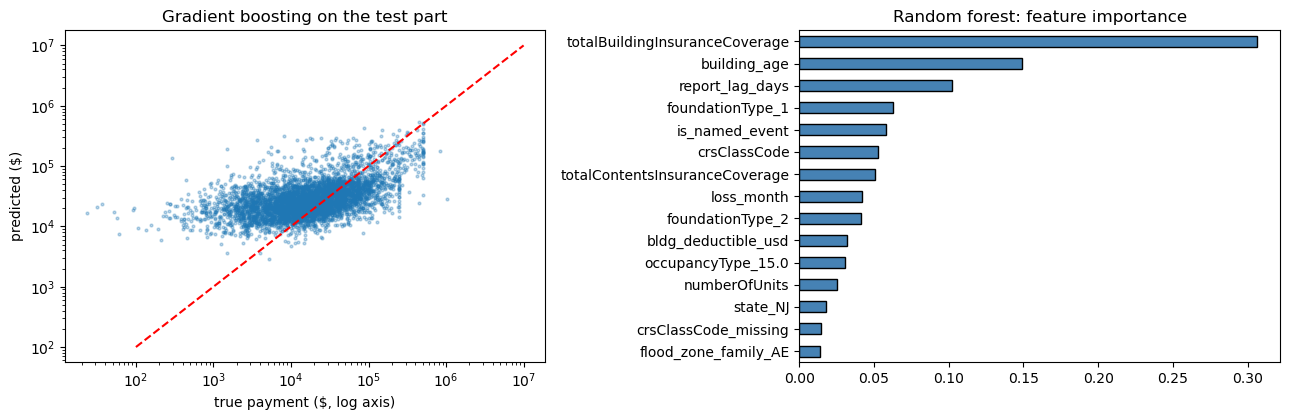

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
idx = np.random.default_rng(SEED).choice(te1.sum(), min(5000, te1.sum()), replace=False)
ax[0].scatter(usd[te1].values[idx], p_gb[idx], s=4, alpha=0.3)
ax[0].plot([100, 1e7], [100, 1e7], 'r--'); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('true payment ($, log axis)'); ax[0].set_ylabel('predicted ($)'); ax[0].set_title('Gradient boosting on the test part')
pd.Series(forest.feature_importances_, index=FEAT_RQ1).sort_values().plot.barh(ax=ax[1], color='steelblue', edgecolor='black')
ax[1].set_title('Random forest: feature importance'); plt.tight_layout(); plt.show()

## 10.1 Geographic features

The question names **geographic features**. Our models use geography through `flood_zone_family`, `crsClassCode`
(a score for the whole community), the **state**, and by training **one model for this region**.
Latitude and longitude were left out (Section 9.1). Here we measure what adding them back would change for the dollar model.

In [22]:
old, new = df['year'] <= 2023, df['year'] >= 2024
rows = []
for label, cols in [('without latitude/longitude', FEAT_RQ1), ('with latitude/longitude', FEAT_RQ1 + COORDS)]:
    r = {'features': label}
    for test_name, a, b in [('random test', train, test), ('new storms (2024-25)', old, new)]:
        a1, b1 = a & rows1, b & rows1
        r[f'R2 dollars, {test_name}'] = r2_score(usd[b1], boosting().fit(X_all.loc[a1, cols], usd[a1]).predict(X_all.loc[b1, cols]))
    rows.append(r)
geo = pd.DataFrame(rows).set_index('features')
geo.round(3)

,"R2 dollars, random test","R2 dollars, new storms (2024-25)"
features,,
without latitude/longitude,0.335,0.170
with latitude/longitude,0.370,0.176


**Reading the check.** Here coordinates help a little in both tests (random 0.335 → 0.370; new storms 0.170 → 0.176).
This region does not have the memorising problem. We still leave them out to use one rule for all regions;
the cost is about 0.03 R². Geography stays in the model through the state, flood zone and CRS class.
On new storms this region's dollar model holds up best of the three (R² 0.17).

## Answer to RQ1 (Mid-Atlantic & Northeast): can we predict the dollar amount paid?

| Model | R² dollars | Median error | Mean error |
|---|---|---|---|
| Baseline (median) | -0.10 | $12,248 | $30,534 |
| Ridge (log → $) | 0.06 | $10,564 | $28,394 |
| Random forest (log → $) | 0.20 | **$9,903** | **$26,736** |
| **Gradient boosting ($)** | **0.34** | $14,828 | $28,146 |

**Only partly.** Gradient boosting explains about **34%** of building payments in dollars, the lowest of the three regions.
Claims here are small and similar (median $16,286), and city flash floods depend on local rain that is not in our data.
For a typical claim the random forest is closest (median error $9,903 vs $12,248 for the baseline).
The most useful facts are **coverage**, **building age**, **report delay**, **slab foundation**, **named storm** and **CRS class**.

---
# Section 11: RQ2 Classification: Is the claim high severity?
Logistic regression, Decision tree (depth from CV), Random forest; `class_weight='balanced'` for the imbalance.

In [23]:
tr2, te2 = train & rows2, test & rows2
X2, X2_lin = X_all[FEAT_RQ2], for_linear(X_all[FEAT_RQ2])
cv2 = StratifiedKFold(5, shuffle=True, random_state=SEED)
depths = range(2, 13)
dscore = [cross_val_score(DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=SEED),
                          X2.loc[s2], y2[s2], cv=cv2, scoring='f1').mean() for d in depths]
best_depth = list(depths)[int(np.argmax(dscore))]
print('Best tree depth (CV F1):', best_depth)
print(f"Baseline 'never severe' on test: accuracy {accuracy_score(y2[te2], np.zeros(te2.sum())):.1%}, recall 0%")

models = {'Logistic regression': (make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000)), X2_lin),
          'Decision tree': (DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=SEED), X2),
          'Random forest': (RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight='balanced', n_jobs=-1, random_state=SEED), X2)}
rows, preds = [], {}
for name, (m, X) in models.items():
    cvf1 = cross_val_score(m, X.loc[s2], y2[s2], cv=cv2, scoring='f1').mean()
    m.fit(X[tr2], y2[tr2]); p = m.predict(X[te2]); pr = m.predict_proba(X[te2])[:, 1]; preds[name] = p
    rows.append({'model': name, 'CV F1': cvf1, 'accuracy': accuracy_score(y2[te2], p), 'precision': precision_score(y2[te2], p),
                 'recall': recall_score(y2[te2], p), 'F1': f1_score(y2[te2], p), 'ROC-AUC': roc_auc_score(y2[te2], pr)})
rq2 = pd.DataFrame(rows).set_index('model')
best2 = rq2['F1'].idxmax()
tn, fp, fn, tp = confusion_matrix(y2[te2], preds[best2]).ravel()
print(f'Best by test F1: {best2}. Found {tp:,} of {tp + fn:,} severe claims ({tp / (tp + fn):.0%}); false alarms on {fp / (tn + fp):.0%} of the others.')
rq2.round(3)

Best tree depth (CV F1): 9
Baseline 'never severe' on test: accuracy 80.5%, recall 0%


Best by test F1: Random forest. Found 975 of 1,440 severe claims (68%); false alarms on 23% of the others.


,CV F1,accuracy,precision,recall,F1,ROC-AUC
model,,,,,,
Logistic regression,0.465,0.709,0.361,0.644,0.463,0.753
Decision tree,0.468,0.729,0.387,0.669,0.490,0.755
Random forest,0.509,0.756,0.421,0.677,0.519,0.798


## Answer to RQ2 (Mid-Atlantic & Northeast)

High severity here = building damage of **$44,302** or more (a third of Florida's level).

| Model | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Logistic regression | 0.36 | 0.64 | 0.46 | 0.75 |
| Decision tree | 0.39 | 0.67 | 0.49 | 0.76 |
| **Random forest** | **0.42** | 0.68 | **0.52** | **0.80** |

**Yes, moderately.** The random forest finds **68%** of high-severity claims (975 of 1,440), with false alarms on 23% of the others.

---
# Section 12: RQ3 Clustering and PCA: Which building profiles exist?
Features: flood zone, foundation, building age, floors, occupancy, CRS class, coverage. Claims with no recorded foundation
(code 0, legacy only) are left out. Payment and damage are **not** used to form groups.

In [24]:
NOM3 = ['flood_zone_family', 'foundationType', 'numberOfFloorsInTheInsuredBuilding', 'occupancyType']
NUM3 = ['building_age', 'crsClassCode', 'totalBuildingInsuranceCoverage']
w3 = work[work['foundationType'] != '0']
s3 = w3.sample(min(20000, len(w3)), random_state=SEED).copy()
X3 = pd.get_dummies(s3[NOM3 + NUM3], columns=NOM3, dtype=int)
X3['totalBuildingInsuranceCoverage'] = np.log1p(X3['totalBuildingInsuranceCoverage'])
Z3 = StandardScaler().fit_transform(X3)
ks = range(2, 9)
sil = [silhouette_score(Z3, KMeans(k, n_init=10, random_state=SEED).fit(Z3).labels_, sample_size=5000, random_state=SEED) for k in ks]
best_k = list(ks)[1:][int(np.argmax(sil[1:]))]          # rule: best silhouette between 3 and 8
print(pd.DataFrame({'k': list(ks), 'silhouette': np.round(sil, 3)}).to_string(index=False))
print('Chosen k:', best_k)

kmeans = KMeans(best_k, n_init=10, random_state=SEED).fit(Z3)
s3['cluster'] = kmeans.labels_
sub = np.random.default_rng(SEED).choice(len(Z3), min(5000, len(Z3)), replace=False)
hier = fcluster(linkage(Z3[sub], method='ward'), t=best_k, criterion='maxclust')
print(f'Silhouette: K-means {silhouette_score(Z3[sub], kmeans.labels_[sub]):.3f}, hierarchical {silhouette_score(Z3[sub], hier):.3f};'
      f' agreement (ARI) {adjusted_rand_score(kmeans.labels_[sub], hier):.3f}')

 k  silhouette
 2       0.844
 3       0.146
 4       0.133
 5       0.123
 6       0.141
 7       0.192
 8       0.169
Chosen k: 7


Silhouette: K-means 0.184, hierarchical 0.173; agreement (ARI) 0.596


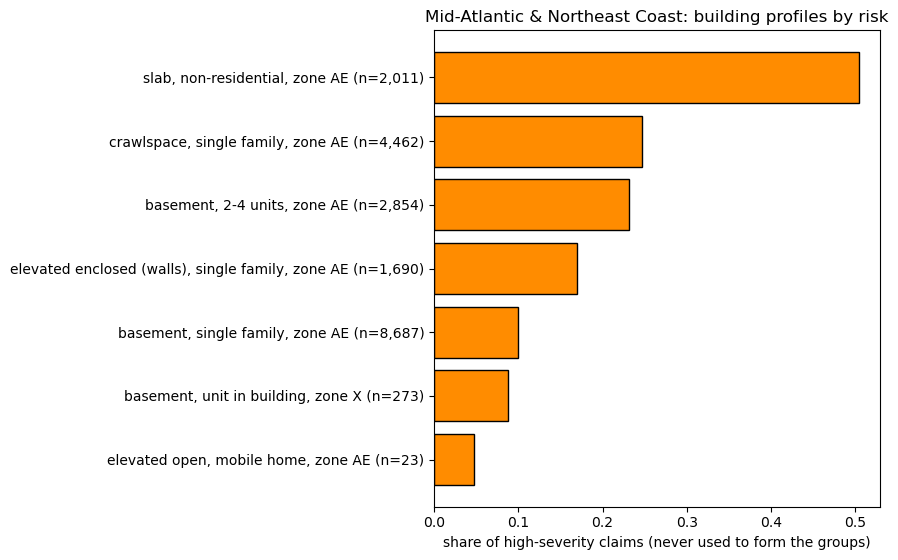

,claims,median_age,median_coverage,high_severity,paid_share,median_payment,foundation,occupancy,zone
cluster,,,,,,,,,
4,2011,59.529,385000.0,0.504,0.656,55344.715,slab,non-residential,AE
5,4462,60.439,250000.0,0.247,0.764,21786.450,crawlspace,single family,AE
3,2854,71.170,250000.0,0.231,0.817,20162.740,basement,2-4 units,AE
0,1690,53.667,250000.0,0.170,0.803,16931.150,elevated enclosed (walls),single family,AE
1,8687,68.969,250000.0,0.100,0.805,12673.820,basement,single family,AE
6,273,46.639,140000.0,0.088,0.421,14096.090,basement,unit in building,X
2,23,32.131,100000.0,0.048,0.739,5529.720,elevated open,mobile home,AE


In [25]:
FOUNDATION = {'1': 'slab', '2': 'basement', '3': 'crawlspace', '4': 'elevated open', '5': 'elevated enclosed (piles)', '6': 'elevated enclosed (walls)'}
OCCUPANCY = {11: 'single family', 12: '2-4 units', 13: '5+ units', 14: 'mobile home', 15: 'condo building', 16: 'unit in building',
             17: 'non-res. mobile', 18: 'non-residential', 19: 'non-res. unit'}
profile = s3.groupby('cluster').agg(claims=('cluster', 'size'), median_age=('building_age', 'median'),
                                    median_coverage=('totalBuildingInsuranceCoverage', 'median'),
                                    high_severity=('high_severity', 'mean'), paid_share=('is_paid', 'mean'),
                                    median_payment=('amountPaidOnBuildingClaim', lambda x: x[x > 0].median()))
profile['foundation'] = s3.groupby('cluster')['foundationType'].agg(lambda x: FOUNDATION.get(x.value_counts().index[0], '?'))
profile['occupancy'] = s3.groupby('cluster')['occupancyType'].agg(lambda x: OCCUPANCY.get(x.value_counts().index[0], '?'))
profile['zone'] = s3.groupby('cluster')['flood_zone_family'].agg(lambda x: x.value_counts().index[0])
profile = profile.sort_values('high_severity', ascending=False)
labels = [f"{r.foundation}, {r.occupancy}, zone {r.zone} (n={r.claims:,})" for r in profile.itertuples()]
plt.figure(figsize=(9, 0.6 * len(profile) + 1.5))
plt.barh(labels[::-1], profile['high_severity'].values[::-1], color='darkorange', edgecolor='black')
plt.xlabel('share of high-severity claims (never used to form the groups)'); plt.title(f'{REGION}: building profiles by risk')
plt.tight_layout(); plt.show()
profile.round(3)

In [26]:
pca = PCA(random_state=SEED).fit(Z3)
cum = np.cumsum(pca.explained_variance_ratio_)
n_keep = int(np.argmax(cum >= 0.80) + 1)
load = pd.DataFrame(pca.components_[:2].T, index=X3.columns, columns=['PC1', 'PC2'])
for pc in ['PC1', 'PC2']:
    t5 = load[pc].reindex(load[pc].abs().sort_values(ascending=False).index).head(5)
    print(pc, f'({pca.explained_variance_ratio_[int(pc[-1]) - 1]:.1%}):', t5.round(2).to_dict())
Zp = pca.transform(Z3)[:, :n_keep]
km_p = KMeans(best_k, n_init=10, random_state=SEED).fit(Zp)
print(f'PCA keeps {n_keep} of {X3.shape[1]} columns for {cum[n_keep - 1]:.1%} of the variance (80% rule)')
print(f"Silhouette: all columns {silhouette_score(Z3, kmeans.labels_, sample_size=5000, random_state=SEED):.3f}, "
      f"PCA {silhouette_score(Zp, km_p.labels_, sample_size=5000, random_state=SEED):.3f}; "
      f'agreement (ARI) {adjusted_rand_score(kmeans.labels_, km_p.labels_):.3f}')

PC1 (8.3%): {'foundationType_2': 0.43, 'occupancyType_18.0': -0.39, 'foundationType_1': -0.39, 'occupancyType_11.0': 0.36, 'flood_zone_family_X': 0.27}
PC2 (7.0%): {'numberOfFloorsInTheInsuredBuilding_5.0': 0.59, 'occupancyType_14.0': 0.57, 'occupancyType_11.0': 0.22, 'occupancyType_18.0': -0.19, 'occupancyType_17.0': 0.17}


PCA keeps 17 of 29 columns for 81.1% of the variance (80% rule)


Silhouette: all columns 0.192, PCA 0.198; agreement (ARI) 0.356


## Answer to RQ3 (Mid-Atlantic & Northeast)

K-means found **7 groups**, but the silhouette is low (0.18; hierarchical 0.17; ARI 0.60), so the groups overlap a lot:

| Profile | Claims | High severity | Median payment |
|---|---|---|---|
| Slab, **non-residential**, zone AE | 2,011 | **50.4%** | $55,345 |
| Crawlspace, single family | 4,462 | 24.7% | $21,786 |
| Basement, 2-4 units (oldest, ~71 yrs) | 2,854 | 23.1% | $20,163 |
| Elevated (walls), single family | 1,690 | 17.0% | $16,931 |
| **Basement, single family** | 8,687 | 10.0% | $12,674 |
| Basement, unit in building, zone X | 273 | 8.8% | $14,096 |

(A group of 23 mobile homes is too small to read.)

**Answer.** Here the clear risk group is **businesses in slab buildings**: half of their claims are high severity.
The most common home, a **single-family house with a basement**, is the largest group but has a low share (10%).
Older multi-unit basement buildings are riskier (23%).

**PCA:** 17 of 29 columns keep 81% of the variance. PC1 (8%) = single-family homes with basements vs non-residential slab buildings;
PC2 (7%) = mobile homes. Clustering on PCA gave almost the same silhouette (0.20 vs 0.19) but different groups (ARI 0.36).
PCA **made no real difference**.

---
# Section 13: Summary

**Mid-Atlantic & Northeast in one paragraph.** This is the hardest region for predicting payments (R² 0.34 in dollars): claims are small,
similar, and caused by local flash floods. Severity is easier (the random forest finds 68% of high-severity claims).
The clearest risk group is **non-residential slab buildings**, not homes; the common basement home is rarely severe.

**Limitations**
- Hurricane Ida (2021) is about 42% of the claims, so results describe Ida-type floods best.
- The building groups overlap a lot (silhouette 0.18); treat them as tendencies.
- About 27,000 claims over 10 states and DC; small states (DC, DE, RI) have few claims.